https://colab.research.google.com/drive/1-9NBKe1qTV8Ppxzdhzo-w2ers27oQ9Md?usp=sharing

In [3]:
%pip install "datasets==3.6.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 11.4 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
ERROR: pip's dependency reso

In [1]:
from datasets import load_dataset

We will use the `bookcorpus` dataset to train a tokenizer. It may take about
15 minutes or more to download and generate the split for the first time.

It requires approximately 5 GB of memory to load the dataset. Please ensure
you have sufficient memory available. If not, consider loading only a fraction
of the dataset.

In [3]:
ds=load_dataset("bookcorpus/bookcorpus",split="all")


README.md:   0%|          | 0.00/18.5k [00:00<?, ?B/s]

bookcorpus.py:   0%|          | 0.00/3.25k [00:00<?, ?B/s]

The repository for bookcorpus/bookcorpus contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/bookcorpus/bookcorpus.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Generating train split:   0%|          | 0/74004228 [00:00<?, ? examples/s]

NameError: name 'pprint' is not defined

In [4]:
from pprint import pprint
pprint(ds)

Dataset({
    features: ['text'],
    num_rows: 74004228
})


The dataset contains 74 million sentences of varying lengths.

The length of sentences does not affect the training of a tokenizer.

Let's take a look at a few examples from the dataset.

In [5]:
num_samples=6
for idx,sample in enumerate(ds[0:num_samples]['text']):
    print(f'{idx} : {sample}')

0 : usually , he would be tearing around the living room , playing with his toys .
1 : but just one look at a minion sent him practically catatonic .
2 : that had been megan 's plan when she got him dressed earlier .
3 : he 'd seen the movie almost by mistake , considering he was a little young for the pg cartoon , but with older cousins , along with her brothers , mason was often exposed to things that were older .
4 : she liked to think being surrounded by adults and older kids was one reason why he was a such a good talker for his age .
5 : `` are n't you being a good boy ? ''


## Tokenization
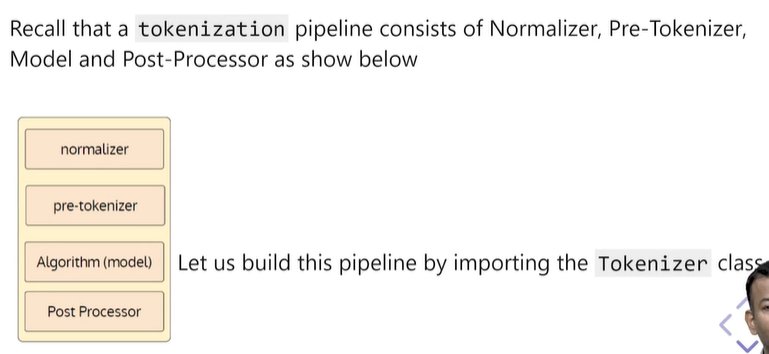

In [7]:
from tokenizers.normalizers import Lowercase
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.models import BPE
from tokenizers import Tokenizer

Initiate the tokenizer with the BPE model and the special tokens ("[UNK]" in
this case) that the model will use during prediction

In [8]:
model=BPE(unk_token="[UNK]")
tokenizer=Tokenizer(model)

Add normalizer and pre-tokenizer to the pipeline


In [9]:
tokenizer.normalizer=Lowercase()
tokenizer.pre_tokenizer=Whitespace()


Create a trainer by setting `vocab_size` and `special_tokens`

In [10]:
from tokenizers.trainers import BpeTrainer
trainer=BpeTrainer(vocab_size=32000,special_tokens=["[PAD]","[UNK]"],continuing_subword_prefix="##")

The pipeline is ready. Next,we need to pass list of strings as input to the
tokenizer

However, creating an additional list containing all 74 million samples will
require an extra 5 GB of memory.

To reduce the memory usage, let us create a generator that returns a batch of
samples as a list



In [11]:
def get_examples(batch_size=1000):
    for i in range(0,len(ds),batch_size):
        yield ds[i:i+batch_size]['text']

Let us train the tokenizer

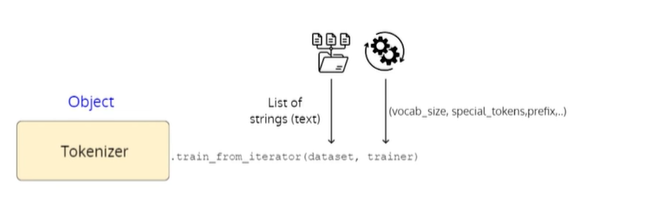

In [12]:
from multiprocessing import cpu_count
print(cpu_count())


2


In [ ]:
tokenizer.train_from_iterator(get_examples(batch_size=10000),trainer=trainer,length=len(ds))

The training took about 5 minutes to complete and required an additional 1
GB of memory.

It would be interesting to see the subtokens that were merged to create the
final vocabulary.

In [ ]:
tokenizer.model.save("model",prefix="hopper")

In [ ]:
with open("model/hopper-merges.txt","r") as file:
    row=0
    num_lines=10
    for line in file.readlines():
        print(line)
        row+=1
        if row>=num_lines:
            break


- Display last `n` merges

In [ ]:
with open("model/hopper-merges.txt","r") as file:
    row=0
    num_lines=10
    for line in reversed(file.readlines()):
        print(line)
        row+=1
        if row>=num_lines:
            break

## Vocabulary


In [ ]:
# lets view the number of merges
with open("model/hopper-merges.txt",'r') as file:
    lines=file.readlines()


In [ ]:
print(f"Number of merges: {len(lines)}")

In [ ]:
print(f"vocab size: {tokenizer.get_vocab_size()}")

The number of merges is slightly less than the size of the vocabulary because
the merges do not include single-character tokens, such as letters, numbers
and special symbols.

We can view the final learned vocabulary either from the saved hopper-
vocab. json file or by using the get_vocab method.

In [ ]:
vocab=tokenizer.get_vocab()

For convenience, let's print the vocabulary sorted by token ID's

In [ ]:
vocab_sorted=sorted(vocab.items(),key=lambda item:item[1])

Let's adjust the sliders below to view the merged subwords and their
corresponding tokens in the vocabulary.

In [ ]:

# _= interact(get_pairs,pair=widgets.IntSlider(min=1, max=len(lines)-1, step=1,
# value=1, layout=Layout(width='900px')))
# 2 _ = interact(display_token_id,id=widgets.IntSlider(min=0, max=31999, step=1,
# value=130,layout=Layout(width='900px')))

Note that the 130th ID represents the first merge. What will the next two
tokens to be merged be? You can explore this by moving the sliders.

The sub-words are `t` and `##he`. After the merge, they will form the token
`the`.